# Modellierung

## Init

In [5]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [6]:
# Prepare features and target
X = df[['calls', 'n_duty', 'n_sby', 'sby_need', 'dafted', 'month', 'day_of_week']]
y = df['n_sick']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modellierungvergleiche

In [13]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 11.676452670902114, MSE: 204.36598352304367, RMSE: 14.295663101900649, R2: 0.09522246497698439, "Training Time (s)" : 0.002895355224609375
Decision Tree - MAE: 13.79004329004329, MSE: 294.79978354978357, RMSE: 17.16973452182018, R2: -0.305149794928647, "Training Time (s)" : 0.0050144195556640625
Random Forest - MAE: 10.6368719851577, MSE: 176.8529450453564, RMSE: 13.298606883630946, R2: 0.21702932689061782, "Training Time (s)" : 0.20899009704589844
Gradient Boosting - MAE: 9.961639486168114, MSE: 150.2244709799115, RMSE: 12.256609277443395, R2: 0.3349200086519536, "Training Time (s)" : 0.06688308715820312
Support Vector Machine - MAE: 12.137011861155777, MSE: 221.92660744726803, RMSE: 14.897201329352706, R2: 0.01747734441569304, "Training Time (s)" : 0.02237415313720703
K-Nearest Neighbors - MAE: 13.351515151515152, MSE: 276.52900432900435, RMSE: 16.629161263545566, R2: -0.22426064546575541, "Training Time (s)" : 0.000980377197265625
Neural Network - MAE: 13.75

Models sorted by MAE:
                              MAE         MSE       RMSE        R2  \
Gradient Boosting        9.961639  150.224471  12.256609  0.334920   
Random Forest           10.636872  176.852945  13.298607  0.217029   
XGBoost                 11.571781  202.644004  14.235308  0.102846   
Linear Regression       11.676453  204.365984  14.295663  0.095222   
Ridge Regression        11.676483  204.366803  14.295692  0.095219   
Lasso Regression        11.730344  205.679972  14.341547  0.089405   
Support Vector Machine  12.137012  221.926607  14.897201  0.017477   
K-Nearest Neighbors     13.351515  276.529004  16.629161 -0.224261   
Neural Network          13.753310  296.244441  17.211753 -0.311546   
Decision Tree           13.790043  294.799784  17.169735 -0.305150   

                        Training Time  
Gradient Boosting            0.066883  
Random Forest                0.208990  
XGBoost                      0.038904  
Linear Regression            0.002895  
Ridge R

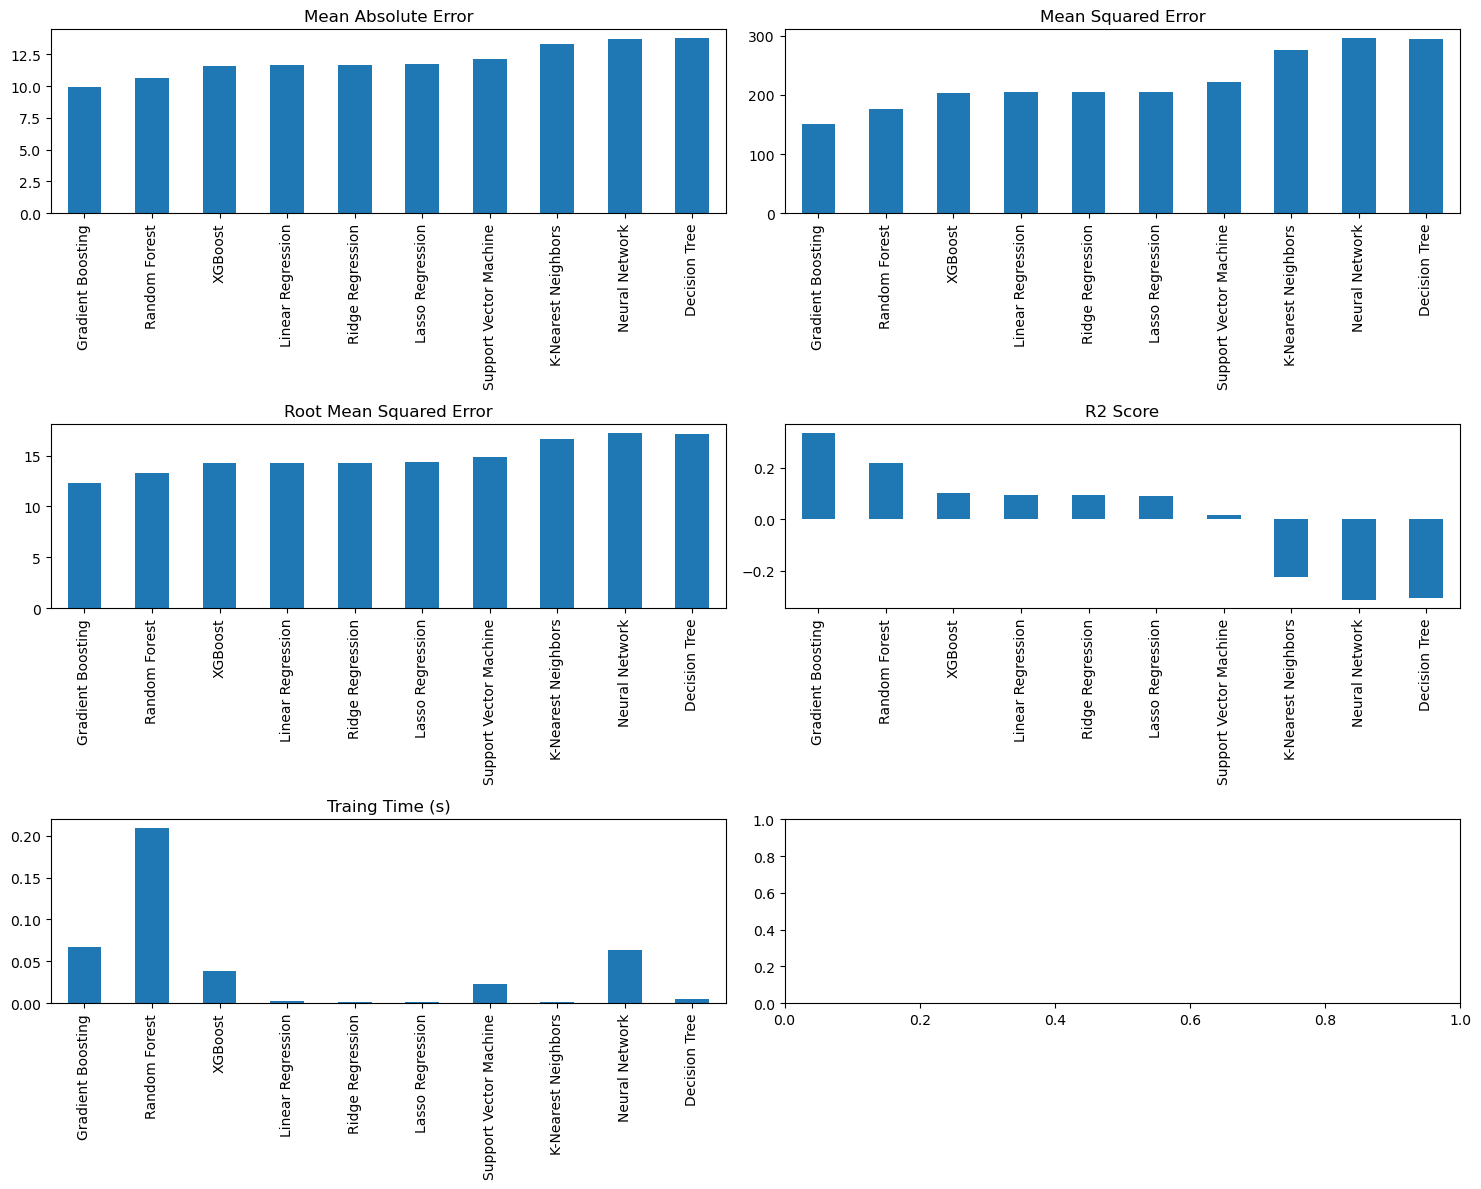

In [15]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
print(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Traing Time (s)')
plt.tight_layout()
plt.show()

In [9]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Gradient Boosting
MAE               7.321730
MSE              84.561597
RMSE              9.195738
R2                0.625625
Training Time     0.082397
Name: Gradient Boosting, dtype: float64


Final Evaluation of the Best Model (Gradient Boosting):
MAE: 7.321729724000432, MSE: 84.56159656254479, RMSE: 9.195737956387447, R2: 0.6256254021509258


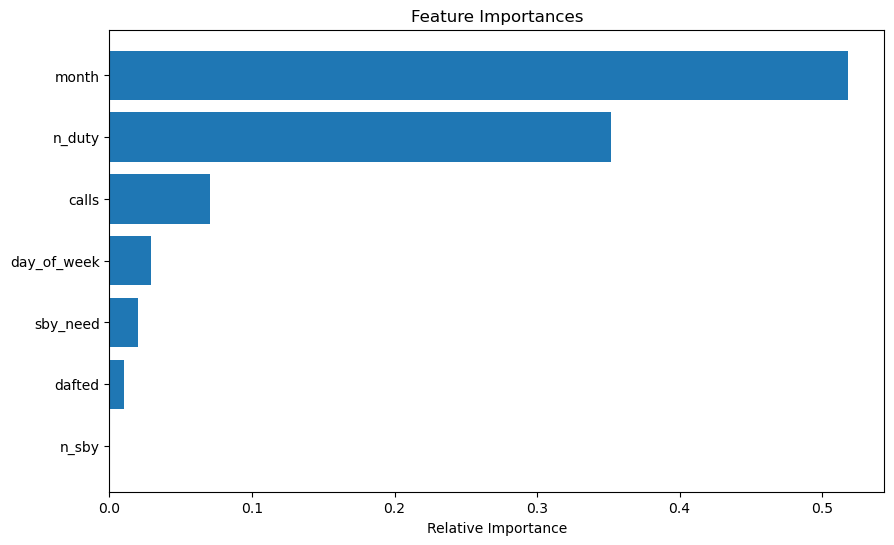

In [10]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


# Modell mit weniger Features (nur die wichtigsten)

In [11]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

X = df[['calls', 'day_of_week', 'month']]
y = df['n_sick']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

# Export model

In [12]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

NameError: name 'scaler' is not defined